In [3]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(2026)

In [4]:
#Punto 1. Integral 1d y 2d más comparación con la integral analitica
def mc_integral_1d(f, a, b, n, rng):
    x = rng.uniform(a, b, n)
    values = f(x)
    volume = b - a
    return volume * values.mean(), volume * values.std(ddof=1) / np.sqrt(n)
def mc_integral_2d(f, ax, bx, ay, by, n, rng):
    x = rng.uniform(ax, bx, n)
    y = rng.uniform(ay, by, n)
    values = f(x, y)
    volume = (bx - ax) * (by - ay)
    return volume * values.mean(), volume * values.std(ddof=1) / np.sqrt(n)
I1_exact = 16 / 3
I2_exact = 2 / 3
sample_sizes = [100, 1000, 10000, 100000]
print(' N       I1 ± SE            error I1      I2 ± SE             error I2')
for n in sample_sizes:
    i1, se1 = mc_integral_1d(np.sqrt, 0, 4, n, rng)
    i2, se2 = mc_integral_2d(lambda x, y: x * y**2, 0, 2, 0, 1, n, rng)
    print(f'{n:6d}  {i1:.6f} ± {se1:.6f}    {abs(i1-I1_exact):.6f}    '
          f'{i2:.6f} ± {se2:.6f}    {abs(i2-I2_exact):.6f}')
print(f'Analíticos: I1 = {I1_exact:.6f}; I2 = {I2_exact:.6f}')

 N       I1 ± SE            error I1      I2 ± SE             error I2
   100  5.510047 ± 0.169350    0.176714    0.695274 ± 0.076915    0.028607
  1000  5.452305 ± 0.058829    0.118972    0.651570 ± 0.024797    0.015097
 10000  5.361687 ± 0.018772    0.028354    0.649445 ± 0.007794    0.017222
100000  5.319310 ± 0.005978    0.014023    0.663261 ± 0.002483    0.003406
Analíticos: I1 = 5.333333; I2 = 0.666667


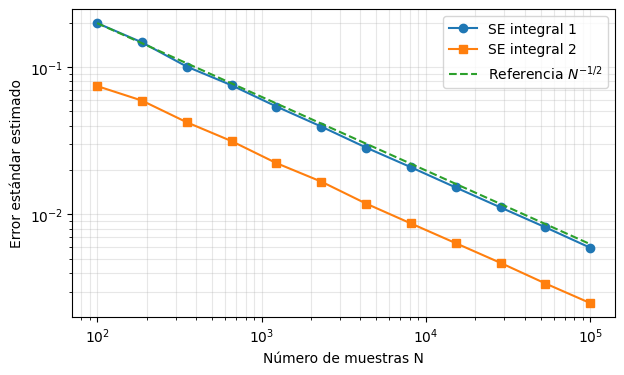

In [5]:
# Comprobar la tendencia del error estadístico (SE) en escala
sizes = np.unique(np.logspace(2, 5, 12, dtype=int))
se1_values = [mc_integral_1d(np.sqrt, 0, 4, n, rng)[1] for n in sizes]
se2_values = [mc_integral_2d(lambda x,y: x*y*y, 0,2,0,1,n,rng)[1] for n in sizes]
plt.figure(figsize=(7, 4))
plt.loglog(sizes, se1_values, 'o-', label='SE integral 1')
plt.loglog(sizes, se2_values, 's-', label='SE integral 2')
plt.loglog(sizes, se1_values[0] * (sizes / sizes[0])**(-0.5), '--', label=r'Referencia $N^{-1/2}$')
plt.xlabel('Número de muestras N')
plt.ylabel('Error estándar estimado')
plt.legend(); plt.grid(True, which='both', alpha=0.3); plt.show()

In [6]:
#Segunda parte
MU_B_OVER_KB = 9.2740100783e-24 / 1.380649e-23
def metropolis_sweep(spins, field_t, temp_k, j_over_kb, rng, masks):
    """Barrido checkerboard: dos subconjuntos de sitios actualizados sucesivamente."""
    for mask in masks:
        neighbors = (np.roll(spins, 1, 0) + np.roll(spins, -1, 0) +
                     np.roll(spins, 1, 1) + np.roll(spins, -1, 1))
        delta_over_kb = 2 * spins * (j_over_kb * neighbors + MU_B_OVER_KB * field_t)
        # Evita overflow: si delta <= 0 se acepta automáticamente.
        accepted = (delta_over_kb <= 0) | (rng.random(spins.shape) < np.exp(-np.maximum(delta_over_kb, 0) / temp_k))
        spins[mask & accepted] *= -1
    return spins
def ising_magnetization_vs_field(temps=(5,10,15), fields=None,L=10, j_over_kb=1.0,thermal_sweeps=200, measure_sweeps=300,seed=2026):
    if L % 2: raise ValueError('L debe ser par para checkerboard periódico')
    if fields is None: fields = np.linspace(-30, 30, 61)
    rng = np.random.default_rng(seed)
    ii, jj = np.indices((L, L))
    even = (ii + jj) % 2 == 0
    masks = (even, ~even)
    results = {}
    for T in temps:
        magnetizations = []
        for H in fields:
            spins = rng.choice([-1, 1], size=(L,L))
            for _ in range(thermal_sweeps):
                metropolis_sweep(spins, H, T, j_over_kb, rng, masks)
            measurements = np.empty(measure_sweeps)
            for t in range(measure_sweeps):
                metropolis_sweep(spins, H, T, j_over_kb, rng, masks)
                measurements[t] = spins.mean()  # m in [-1,1]
            magnetizations.append(measurements.mean())
        results[T] = np.asarray(magnetizations)
    return np.asarray(fields), results

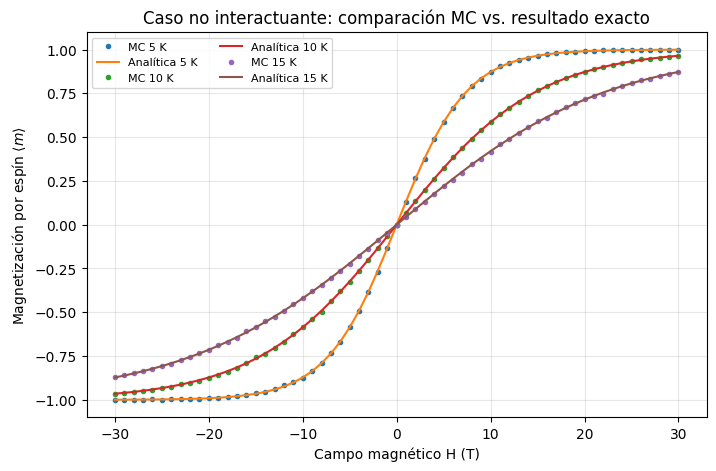

T =  5 K, RMSE = 0.00225
T = 10 K, RMSE = 0.00239
T = 15 K, RMSE = 0.00325


In [8]:
# Comparación donde la fórmula analítica sí aplica: J = 0
f0, res0 = ising_magnetization_vs_field(j_over_kb=0.0, seed=2027)
fig, ax = plt.subplots(figsize=(8,5))
for T, mvals in res0.items():
    ax.plot(f0, mvals, 'o', ms=3, label=f'MC {T} K')
    ax.plot(f0, np.tanh(MU_B_OVER_KB * f0 / T), '-', label=f'Analítica {T} K')
ax.set_xlabel('Campo magnético H (T)')
ax.set_ylabel(r'Magnetización por espín $\langle m\rangle$')
ax.set_title('Caso no interactuante: comparación MC vs. resultado exacto')
ax.legend(ncol=2, fontsize=8); ax.grid(alpha=0.3); plt.show()
for T in res0:
    exact = np.tanh(MU_B_OVER_KB * f0 / T)
    rmse = np.sqrt(np.mean((res0[T]-exact)**2))
    print(f'T = {T:2d} K, RMSE = {rmse:.5f}')

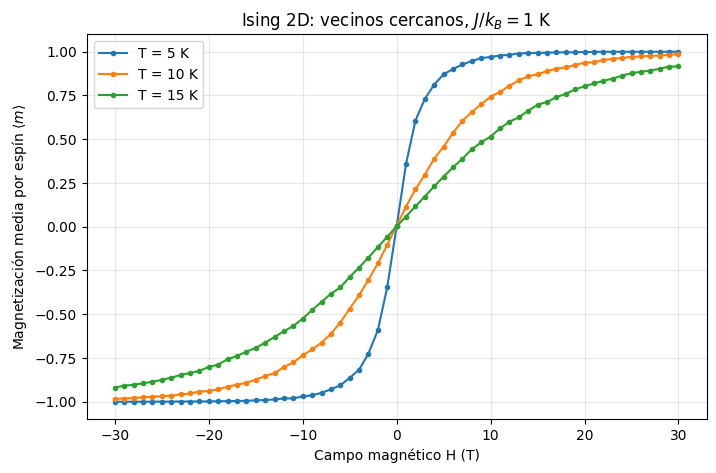

In [7]:
# Simulación con interacción entre primeros vecinos
fields, results = ising_magnetization_vs_field(j_over_kb=1.0)

plt.figure(figsize=(8,5))
for T, mvals in results.items():
    plt.plot(fields, mvals, 'o-', ms=3, label=f'T = {T} K')
plt.xlabel('Campo magnético H (T)')
plt.ylabel(r'Magnetización media por espín $\langle m\rangle$')
plt.title(r'Ising 2D: vecinos cercanos, $J/k_B=1$ K')
plt.legend(); plt.grid(alpha=0.3); plt.show()

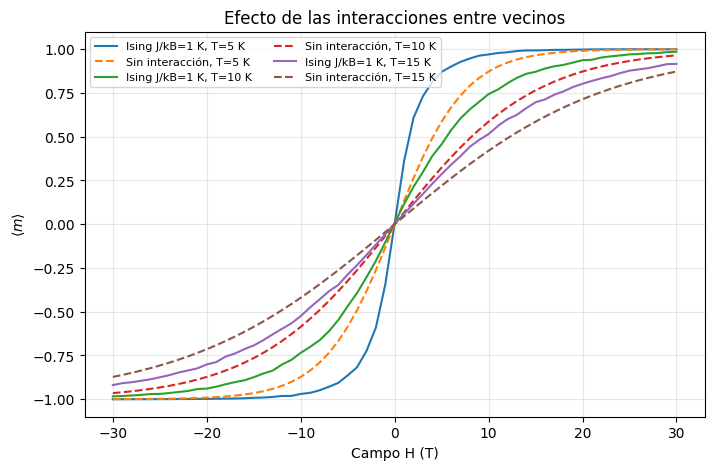

In [9]:
# Comparación de respuesta magnética cuando hay interacción vs. sin interacción
plt.figure(figsize=(8,5))
for T in (5,10,15):
    plt.plot(fields, results[T], label=f'Ising J/kB=1 K, T={T} K')
    plt.plot(fields, np.tanh(MU_B_OVER_KB * fields / T), '--',
             label=f'Sin interacción, T={T} K')
plt.xlabel('Campo H (T)')
plt.ylabel(r'$\langle m \rangle$')
plt.title('Efecto de las interacciones entre vecinos')
plt.legend(ncol=2, fontsize=8); plt.grid(alpha=0.3); plt.show()

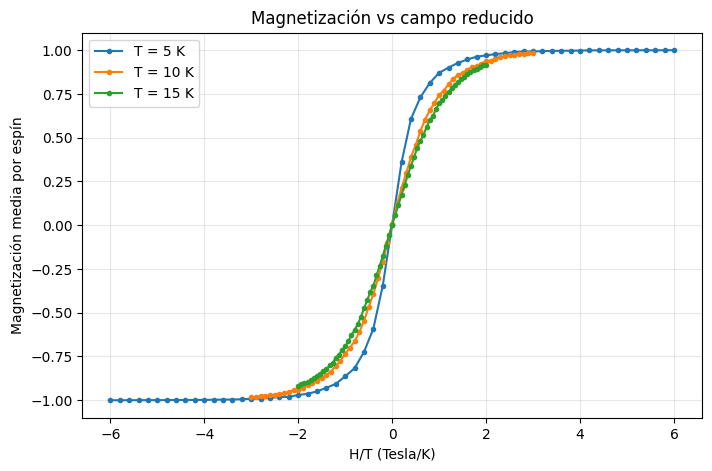

In [10]:
plt.figure(figsize=(8, 5))
for T, mvals in results.items():
    plt.plot(fields / T, mvals, 'o-', ms=3, label=f'T = {T} K')
plt.xlabel('H/T (Tesla/K)')
plt.ylabel('Magnetización media por espín')
plt.title('Magnetización vs campo reducido')
plt.legend()
plt.grid(alpha=0.3)
plt.show()